## Analysis on agents/users who browse alot but are low frequency buyers 

This analysis finds the agents who browse product son yhe PWA platform but write relatively few policies, and separates agents whose business is slowing from those still producing. It covers the 420 agents on the 'Low frewuency(browse over buy)' tab of tje warehouse-verified extract dated October 8, 2026


We are moving agents from the old agent platform to the PWA. Product-view tracking on the PWA began around Sep 30, 2026, so September 30th is the dividing line: sales before it show each agent's history, and sales since it show current activity.Comparing the two shows who has slowed down, not just who sells little.

The analysis treats browsing, quotes, policies created and paid  business as different signals. A product view or a quote is not a sale, and a policy written is not proof of payment. Keeping them apart avoids labelling a busy browser as productive, or a busy seller on the old platform as a dropper.



## Data Understanding


The tab holds 420  agents, one row each, with 10 columns and no duplicate rows, names, emails or phone numbers. Every agent made at least one sale since September 30 and viewed at least 2 products, so the tab is a filtered group, not the full agent roster.

#### *Source and Scope*

- File: 'Lami- Droppers + Low-freq buyers(warehouse-verified, Oct 8 2026)' second sheet. The first sheet holds 151 agents with no sales since September 30th.

- Period: Since September 30th to 0ctober 8th, 2026(about 8 days), inferred from the column names and the file date. No row carries a date.

- Sort order: by viewed_per_sale, highest first.
- Comparison point: te earlier 'Dropper lists (September 30-Oct 3 2026)' sheet , where 269 of these agents also apppear.

In [ ]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

In [67]:
droppers = pd.read_csv('droppers.csv')

droppers.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,DATES
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,254712129778,NaN
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com,254720925163,NaN
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com,254724589595,NaN
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com,254719750454,NaN
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com,254722139396,NaN


In [68]:
#Number of viewed aevents
droppers['view_events'].sum()
print("Total number of viewed events:", droppers['view_events'].sum())

#Intent; total quotes created(all time)
droppers['quotes_alltime'].sum()
print("Total number of quotes created:", droppers['quotes_alltime'].sum())

#Sales created since September 30th 
droppers['sales_since_sep30'].sum()
print("Total number of sales created since September 30th:", droppers['sales_since_sep30'].sum())



Total number of viewed events: 5773
Total number of quotes created: 176636
Total number of sales created since September 30th: 2967


#### *Activity versus business*

• Activity: 5,773 view events. Shows interest only.

• Intent: 176,636 lifetime quotes. Undated, and 180 agents have more sales than quotes, so quotes do not capture every sale.

• Policies created: 2,967 since Sep 30. The tab does not say whether they were paid or which platform they came from.

• Paid business: not on this tab. Hand checks from Oct 3 cover 34 of these agents: 301 sales, 53 unpaid, 268 on the PWA and 33 on the old platform.

### PROBLEM STATEMENT 

LAMI cannot yet tell which agents are losing business and which are still producing, because the data mixes browsing, quotes and policies written, and does not record payment or platform. Every agent on this tab sold at least once since Sep 30, so the risk is a slowdown, not a full stop: an agent who sold hundreds of policies before Sep 30 and only 1 or 2 since looks active on a simple "has sales" check.


The analysis needs to answer five questions:


1. Which agents browse heavily on the PWA but write few policies since Sep 30?

2. Which agents are selling far below their own history before Sep 30?

3. Which agents are actively generating business, and what share of recent sales do they account for?

4. How much of each agent's recorded activity is actual business: policies created, and of those, how many are paid?

5. Where is platform attribution unclear, so that an apparent drop may be selling on the old platform instead?

A good result is a named, prioritised list of slowing and non-converting agents for follow-up, with each classification shown alongside the evidence behind it and its known gaps.

In [69]:
droppers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   products_viewed    420 non-null    int64  
 1   view_events        420 non-null    int64  
 2   sales_since_sep30  420 non-null    int64  
 3   viewed_per_sale    420 non-null    float64
 4   all_sales_alltime  420 non-null    int64  
 5   quotes_alltime     420 non-null    int64  
 6   user_name          420 non-null    object 
 7   county             419 non-null    object 
 8   email              420 non-null    object 
 9   phone_number       420 non-null    int64  
 10  DATES              0 non-null      float64
dtypes: float64(2), int64(6), object(3)
memory usage: 36.2+ KB


In [70]:
droppers = droppers.drop(columns=['DATES','phone_number'])

droppers.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com


In [71]:
droppers.value_counts(['user_name'])

user_name                   
A PLAN Insurance Brokers Ltd    1
Mark Kemei                      1
Moureen Munyiva                 1
Moseti Nyachio Justine          1
Moses Okal                      1
                               ..
Faith Mukavale                  1
FREDRICK OTIENO                 1
FLORENCE MUTHONI NJENGA         1
FELIX BARNGETUNY                1
joseph gatu                     1
Name: count, Length: 420, dtype: int64

### Policies created since September 30th compared to sales done before September 30th

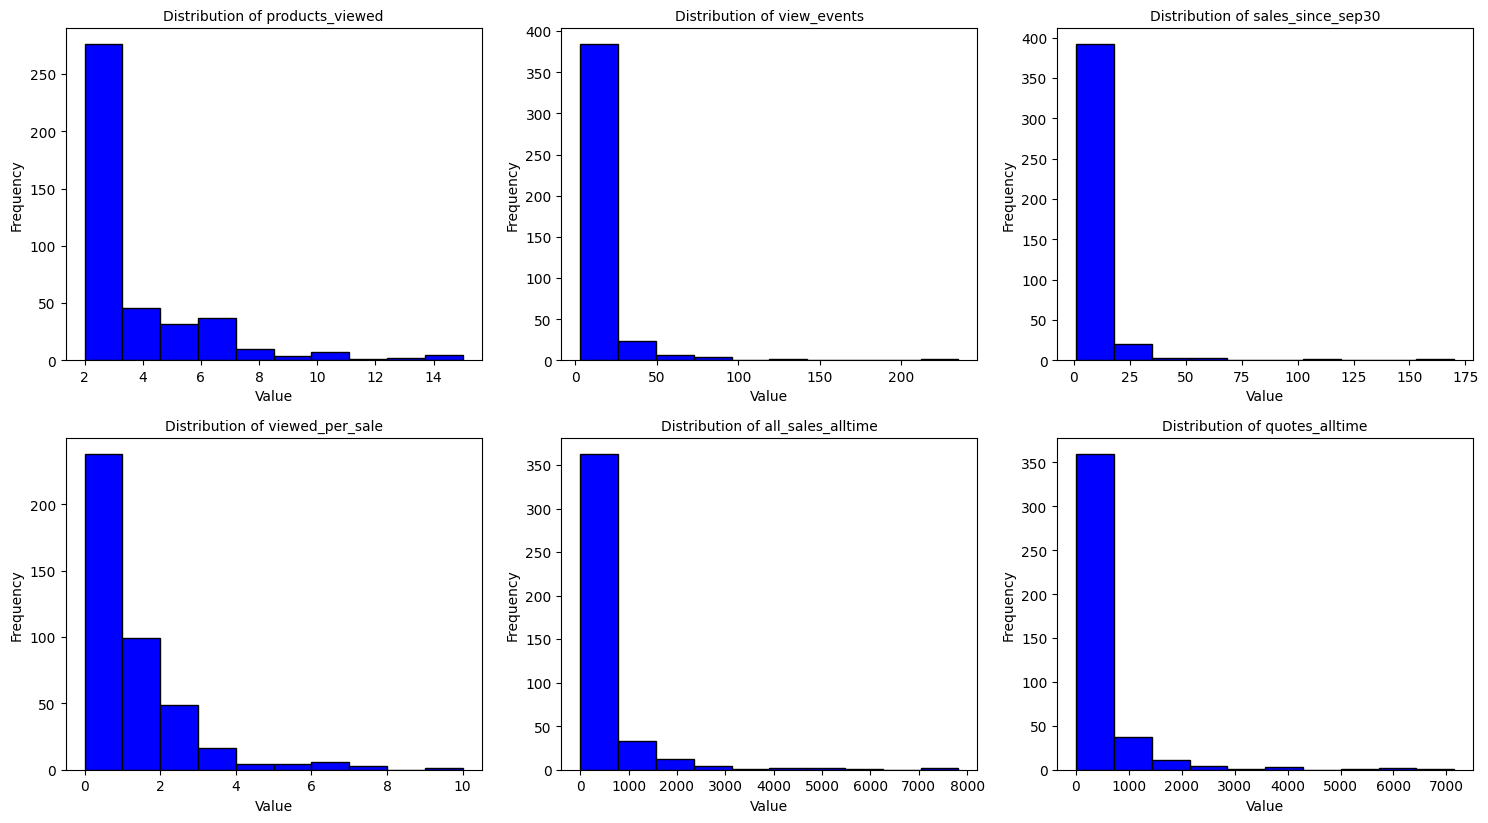

In [72]:
cols = [
    'products_viewed',
    'view_events',
    'sales_since_sep30',
    'viewed_per_sale',
    'all_sales_alltime',
    'quotes_alltime'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].hist(droppers[col].dropna(), bins=10,
                 color='blue', edgecolor='black')
    axes[i].set_title(f'Distribution of {col}', fontsize=10)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Hide the three unused plots
for i in range(len(cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

In [73]:
droppers['sales_before_sept30'] = droppers['all_sales_alltime'] - droppers['sales_since_sep30']

droppers.head(10)

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,sales_before_sept30
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,1
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com,0
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com,168
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com,7
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com,1
5,12,43,2,6.0,4591,3655,Edvan Insurance Agency,Nairobi City,edvanagency@gmail.com,4589
6,6,17,1,6.0,68,87,Tim Gatehi,Nairobi City,timgatehit@gmail.com,67
7,6,16,1,6.0,263,240,Kevin Kwanusu,Nairobi City,kipropkevin93@gmail.com,262
8,6,20,1,6.0,106,120,Phillis Comfort Ngosenywe,Nairobi City,comphy81@gmail.com,105
9,6,14,1,6.0,218,232,Simon Mwandima,Nairobi City,nadimainsurance@gmail.com,217


#### Percentile ranks (0-1). A big gap means an agent was a top seller, but now isn't 

In [74]:
droppers['rank_lifetime'] = droppers['all_sales_alltime'].rank(pct=True)
droppers['rank_recent'] = droppers['sales_since_sep30'].rank(pct=True)
droppers['rank_gap'] = (droppers['rank_lifetime'] - droppers['rank_recent']) *100

In [75]:
median_views = droppers['view_events'].median()
print(f"The median number of view events is: {median_views}")

median_sales = droppers['sales_since_sep30'].median()
print(f"The median number of sales since September 30 is: {median_sales}")

The median number of view events is: 9.0
The median number of sales since September 30 is: 4.0


In [76]:
conditions = [
    droppers['sales_before_sept30'] == 0,  #new agent
    droppers['rank_gap'] > 0,  #declining agent/ slowing vs own history 
    (droppers['view_events'] > median_views) & (droppers['sales_since_sep30'] <= median_sales),  #high view low sales
    droppers['sales_since_sep30'] > median_sales,  #high sales/producing

]

labels = [
    'New Agent',
    'Slowing vs Own History',
    'Browsin, not producing',
    'Producing'
]

droppers['status'] = np.select(conditions, labels, default='Low but steady')

droppers.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,sales_before_sept30,rank_lifetime,rank_recent,rank_gap,status
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,1,0.008333,0.077381,-6.904762,"Browsin, not producing"
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com,0,0.008333,0.236905,-22.857143,New Agent
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com,168,0.473810,0.077381,39.642857,Slowing vs Own History
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com,7,0.046429,0.077381,-3.095238,"Browsin, not producing"
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com,1,0.017857,0.236905,-21.904762,"Browsin, not producing"


### Aggregation of each groups (%) of  total sales in each period

In [77]:
order = ['Slowing vs Own History',
         'Browsin, not producing',
         'Low but steady',
         'Producing',
         'New Agent']        


In [78]:
summary = (
    droppers.groupby('status')[['sales_before_sept30', 'sales_since_sep30']].sum().reindex(order)  
)

print(summary)

share = summary/ summary.sum() *100
print(share.round(1))

                        sales_before_sept30  sales_since_sep30
status                                                        
Slowing vs Own History               109658               1016
Browsin, not producing                 1628                 93
Low but steady                         3105                162
Producing                             73313               1691
New Agent                                 0                  5
                        sales_before_sept30  sales_since_sep30
status                                                        
Slowing vs Own History                 58.4               34.2
Browsin, not producing                  0.9                3.1
Low but steady                          1.7                5.5
Producing                              39.1               57.0
New Agent                               0.0                0.2


In [79]:
share.head(10)

,sales_before_sept30,sales_since_sep30
status,,
Slowing vs Own History,58.420705,34.243343
"Browsin, not producing",0.867323,3.134479
Low but steady,1.654200,5.460061
Producing,39.057772,56.993596
New Agent,0.000000,0.168520


#### Plot grouped horizontal plots

In [80]:
y = np.arange(len(order))  #one slot per group
h= 0.35

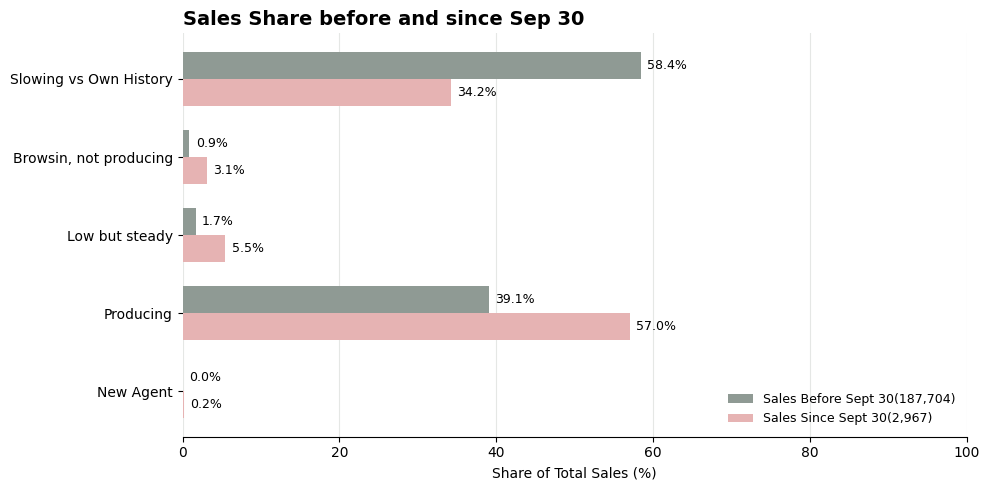

In [81]:
fig, ax = plt.subplots(figsize=(10,5))

ax.barh(y - h/2, share['sales_before_sept30'], height=h, label= f'Sales Before Sept 30({summary["sales_before_sept30"].sum():,.0f})', color='#8f9a94'
        )

ax.barh(y + h/2, share['sales_since_sep30'], height=h, label= f'Sales Since Sept 30({summary["sales_since_sep30"].sum():,.0f})', color='#e6b3b3'
        )

#Value labels at the end of each bar
for i, (b,s) in enumerate (zip(share['sales_before_sept30'], share['sales_since_sep30'])):
    ax.text( b + 0.8, i-h/2, f"{b:.1f}%", va='center', fontsize=9)
    ax.text( s + 0.8, i+h/2, f"{s:.1f}%", va='center', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(order)
ax.invert_yaxis()  #highest at the top
ax.set_xlim(0, 100)
ax.set_xlabel('Share of Total Sales (%)')
ax.set_title('Sales Share before and since Sep 30',loc= 'left', fontweight='bold', fontsize=14)
ax.grid(axis = 'x', color = '#e5e7e5')
ax.set_axisbelow(True)

for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.legend(loc='lower right', fontsize=9, frameon=False)    

plt.tight_layout()
plt.savefig('Share_of_sales.png', dpi=200)
plt.show()

In [82]:



gap = (droppers["all_sales_alltime"].rank(pct=True)
       - droppers["sales_since_sep30"].rank(pct=True)) * 100
mv = droppers["view_events"].median()
ms = droppers["sales_since_sep30"].median()
droppers["status"] = np.select(
    [droppers["sales_before_sept30"] == 0, gap >= 30,
     (droppers["view_events"] > mv) & (droppers["sales_since_sep30"] <= ms),
     droppers["sales_since_sep30"] > ms],
    ["New agent", "Slowing vs own history",
     "Browsing, not converting", "Producing"],
    default="Low but steady")

order = ["Slowing vs own history", "Browsing, not converting",
         "Low but steady", "Producing", "New agent"]
t = (droppers.groupby("status")
       .agg(agents=("user_name", "size"),
            before=("sales_before_sept30", "sum"),
            since=("sales_since_sep30", "sum"))
       .reindex(order))
t.loc["All agents"] = t.sum()
t["share_before"] = t["before"] / t.loc["All agents", "before"] * 100
t["share_since"] = t["since"] / t.loc["All agents", "since"] * 100
t["since_per_1000"] = t["since"] / t["before"].replace(0, np.nan) * 1000
print(t.round(1))



                          agents  before  since  share_before  share_since  \
status                                                                       
Slowing vs own history        44   21899     86          11.7          2.9   
Browsing, not converting      62    7076    170           3.8          5.7   
Low but steady               121   10876    284           5.8          9.6   
Producing                    190  147853   2422          78.8         81.6   
New agent                      3       0      5           0.0          0.2   
All agents                   420  187704   2967         100.0        100.0   

                          since_per_1000  
status                                    
Slowing vs own history               3.9  
Browsing, not converting            24.0  
Low but steady                      26.1  
Producing                           16.4  
New agent                            NaN  
All agents                          15.8  


In [83]:
t.head(10)

,agents,before,since,share_before,share_since,since_per_1000
status,,,,,,
Slowing vs own history,44,21899,86,11.666773,2.898551,3.927120
"Browsing, not converting",62,7076,170,3.769765,5.729693,24.024873
Low but steady,121,10876,284,5.794229,9.571958,26.112541
Producing,190,147853,2422,78.769232,81.631277,16.381135
New agent,3,0,5,0.000000,0.168520,NaN
All agents,420,187704,2967,100.000000,100.000000,15.806802


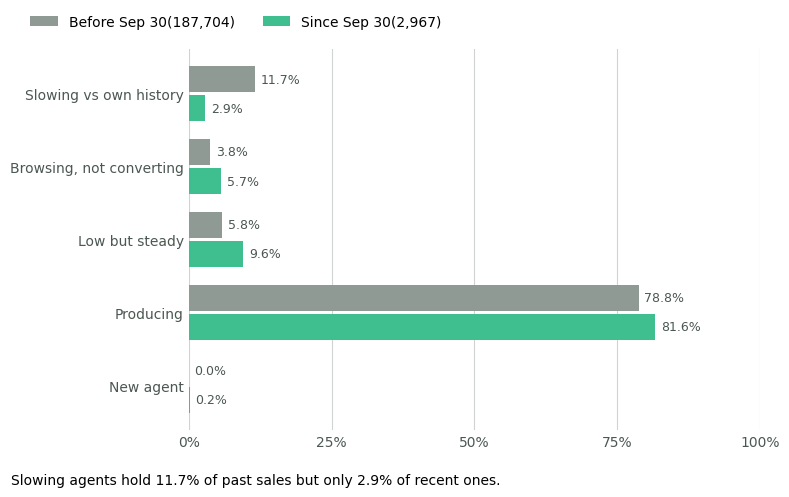

In [84]:
g = t.drop("All agents")
before, since = g["share_before"], g["share_since"]
tot_b, tot_s = int(t.loc['All agents', 'before']), int(t.loc['All agents', 'since'])

GREY, GREEN = "#8f9a94", "#3fbf8f"
y = np.arange(len(g))
h= 0.36

fig, ax = plt.subplots(figsize =(8,5))
ax.barh(y -h/2 - 0.02, before, height=h, color=GREY, label=f'Before Sep 30({tot_b:,})')
ax.barh(y + h/2 + 0.02, since, height=h, color=GREEN, label=f'Since Sep 30({tot_s:,})')

#% label at the end of every bar
for i, (b,s) in enumerate(zip(before, since)):
    ax.text(b + 1, i - h/2 - 0.02, f"{b:.1f}%", va='center', fontsize=9, color= '#4b5751')
    ax.text(s + 1, i + h/2 + 0.02, f"{s:.1f}%", va='center', fontsize=9, color= '#4b5751')

ax.set_yticks(y)
ax.set_yticklabels(g.index, color= '#4b5751')
ax.invert_yaxis()
#first group on top
ax.set_xlim(0, 100)
ax.set_xticks([0,25,50,75,100])
ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'], color= '#4b5751')
ax.grid(axis='x', color='#cfd4d1')
ax.set_axisbelow(True)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
 
ax.legend(loc="lower left", bbox_to_anchor=(-0.3, 1.02), ncol=2, frameon=False)
fig.text(0.02, 0.02, f"Slowing agents hold {before.iloc[0]:.1f}% of past sales "
         f"but only {since.iloc[0]:.1f}% of recent ones.", fontsize=10)
 
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig("share_before_since.png", dpi=200)
plt.show()


### Sales since September 30th

In [85]:
droppers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   products_viewed      420 non-null    int64  
 1   view_events          420 non-null    int64  
 2   sales_since_sep30    420 non-null    int64  
 3   viewed_per_sale      420 non-null    float64
 4   all_sales_alltime    420 non-null    int64  
 5   quotes_alltime       420 non-null    int64  
 6   user_name            420 non-null    object 
 7   county               419 non-null    object 
 8   email                420 non-null    object 
 9   sales_before_sept30  420 non-null    int64  
 10  rank_lifetime        420 non-null    float64
 11  rank_recent          420 non-null    float64
 12  rank_gap             420 non-null    float64
 13  status               420 non-null    object 
dtypes: float64(4), int64(6), object(4)
memory usage: 46.1+ KB


In [86]:
droppers["sales_band"] = pd.cut(
    droppers["sales_since_sep30"],
    bins=[0, 1, 2, 4, 9, 19, 49, np.inf],
    labels=["1", "2", "3-4", "5-9", "10-19", "20-49", "50+"],
)

In [90]:
#TABLE

band_table = ( 
    droppers.groupby('sales_band', observed= False)
    .agg(agents = ('user_name', 'size'),
         policies= ('sales_since_sep30', 'sum'))
)

band_table['share_agents'] = band_table['agents'] / band_table['agents'].sum() * 100
band_table['share_policies'] = band_table['policies'] / band_table['policies'].sum()* 100

print(band_table.round(1))

print("Total agents:", band_table["agents"].sum(), "| Total policies:", band_table["policies"].sum())

            agents  policies  share_agents  share_policies
sales_band                                                
1               64        64          15.2             2.2
2               70       140          16.7             4.7
3-4             94       331          22.4            11.2
5-9            115       743          27.4            25.0
10-19           51       652          12.1            22.0
20-49           21       586           5.0            19.8
50+              5       451           1.2            15.2
Total agents: 420 | Total policies: 2967


In [91]:
#SUMMARY FIGURES

print('Mean:', round(droppers['sales_since_sep30'].mean(), 1),
      '| Median:', droppers['sales_since_sep30'].median()
      )

Mean: 7.1 | Median: 4.0


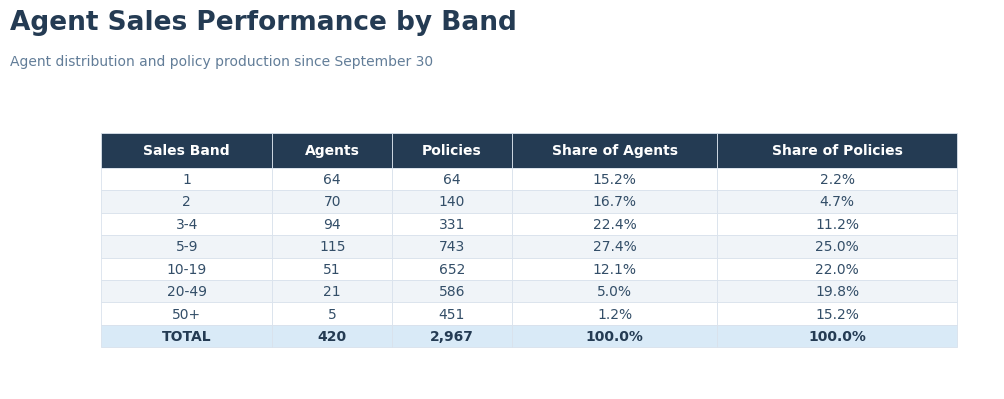

In [ ]:



# Prepare the table for display
display_table = band_table.reset_index()

# Format values for a presentation-ready table
cell_text = []

for _, row in display_table.iterrows():
    cell_text.append([
        str(row["sales_band"]),
        f'{row["agents"]:,.0f}',
        f'{row["policies"]:,.0f}',
        f'{row["share_agents"]:.1f}%',
        f'{row["share_policies"]:.1f}%'
    ])

# Add a totals row
cell_text.append([
    "TOTAL",
    f'{band_table["agents"].sum():,.0f}',
    f'{band_table["policies"].sum():,.0f}',
    "100.0%",
    "100.0%"
])

columns = [
    "Sales Band",
    "Agents",
    "Policies",
    "Share of Agents",
    "Share of Policies"
]

# Create the figure
fig, ax = plt.subplots(figsize=(12, 4.5))
fig.patch.set_facecolor("white")
ax.axis("off")

# Title and subtitle
fig.text(
    0.08, 0.91,
    "Agent Sales Performance by Band",
    fontsize=19, fontweight="bold",
    color="#243B53"
)

fig.text(
    0.08, 0.83,
    "Agent distribution and policy production since September 30",
    fontsize=10, color="#627D98"
)

# Draw the table
table = ax.table(
    cellText=cell_text,
    colLabels=columns,
    cellLoc="center",
    colLoc="center",
    colWidths=[0.20, 0.14, 0.14, 0.24, 0.28],
    bbox=[0.04, 0.12, 0.92, 0.62]
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

# Style header, body, and totals
total_row = len(cell_text)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#D9E2EC")
    cell.set_linewidth(0.6)

    if row == 0:
        cell.set_facecolor("#243B53")
        cell.set_text_props(
            color="white", weight="bold"
        )
        cell.set_height(0.12)

    elif row == total_row:
        cell.set_facecolor("#D9EAF7")
        cell.set_text_props(
            color="#243B53", weight="bold"
        )

    else:
        cell.set_facecolor(
            "#F0F4F8" if row % 2 == 0 else "white"
        )
        cell.set_text_props(color="#334E68")

# Save the image
Path("plots").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "plots/sales_band_table.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [93]:
#CUMULATIVE SHARE

cumulative_share = (
    droppers["sales_since_sep30"].sort_values(ascending=False).cumsum()
    / droppers["sales_since_sep30"].sum()
).reset_index(drop=True)
print("Agents needed for 50% of policies:", (cumulative_share < 0.5).sum() + 1)
print("Top 10 agents' share:", round(cumulative_share[9] * 100, 1), "%")

Agents needed for 50% of policies: 58
Top 10 agents' share: 21.6 %


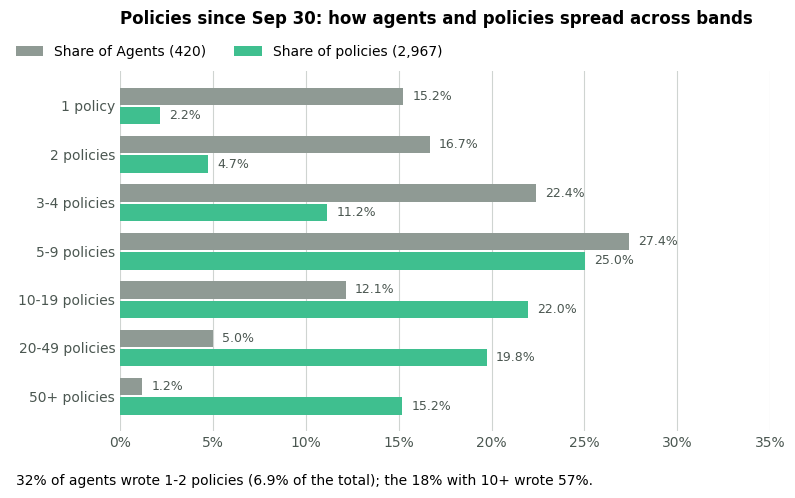

In [96]:
#CHART VISUALIZATION

y= np.arange(len(band_table))

h = 0.36
GREY, GREEN = "#8f9a94", "#3fbf8f"

fig, ax = plt.subplots(figsize = (8,5))
ax.barh(y- h/2 - 0.02, band_table['share_agents'], height=h, color= GREY, 
        label = f'Share of Agents ({band_table["agents"].sum()})')

ax.barh( y + h/2 + 0.02, band_table['share_policies'], height= h, color = GREEN,
        label= f'Share of policies ({band_table["policies"].sum():,})')

for i, (a,p) in enumerate(zip(band_table['share_agents'], band_table['share_policies'])):
    ax.text(a + 0.5, i - h/2 - 0.02, f"{a:.1f}%", va='center', fontsize=9, color= '#4b5751')
    ax.text(p + 0.5, i + h/2 + 0.02, f"{p:.1f}%", va='center', fontsize=9, color= '#4b5751')

ax.set_yticks(y)
ax.set_yticklabels(["1 policy" if b == "1" else f"{b} policies" for b in band_table.index],
                   color="#4b5751")
ax.invert_yaxis()
ax.set_xlim(0, 35)
ax.set_xticks(range(0, 36, 5))
ax.set_xticklabels([f"{v}%" for v in range(0, 36, 5)], color="#4b5751")
ax.grid(axis="x", color="#cfd4d1")
ax.set_axisbelow(True)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
 
ax.set_title("Policies since Sep 30: how agents and policies spread across bands",
             loc="left", fontweight="bold", pad=34)
ax.legend(loc="lower left", bbox_to_anchor=(-0.18, 1.0), ncol=2, frameon=False)
fig.text(0.02, 0.02, "32% of agents wrote 1-2 policies (6.9% of the total); "
         "the 18% with 10+ wrote 57%.", fontsize=10)
 
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig("plots/sales_since_sep30_bands.png", dpi=200)
plt.show()    

A snapshot of all sale activity of the 420 agents we have

In [97]:
if 'sales_before_sept30' in droppers.columns:
    droppers['sales_before_sept30'] = droppers['all_sales_alltime'] - droppers['sales_since_sep30']

In [98]:
droppers.columns

Index(['products_viewed', 'view_events', 'sales_since_sep30',
       'viewed_per_sale', 'all_sales_alltime', 'quotes_alltime', 'user_name',
       'county', 'email', 'sales_before_sept30', 'rank_lifetime',
       'rank_recent', 'rank_gap', 'status', 'sales_band'],
      dtype='object')

In [101]:
#SNAPSHOT OF THE SEVEN COLUMNS

cols = ['view_events',
        'products_viewed',
        'viewed_per_sale',
        'all_sales_alltime',
        'quotes_alltime',
        'sales_before_sept30',
        'sales_since_sep30']


snapshot = droppers[cols].agg(['sum','median','min','max']).T
snapshot

,sum,median,min,max
view_events,5773.0,9.0,3.0,235.0
products_viewed,1540.0,3.0,2.0,15.0
viewed_per_sale,480.8,0.7,0.0,10.0
all_sales_alltime,190671.0,193.5,1.0,7821.0
quotes_alltime,176636.0,180.0,2.0,7148.0
sales_before_sept30,187704.0,190.0,0.0,7760.0
sales_since_sep30,2967.0,4.0,1.0,170.0


In [103]:
snapshot.loc['viewed_per_sale', 'sum']=np.nan

snapshot["window"] = ["Since ~Sep 30", "Since ~Sep 30", "Since ~Sep 30", "Lifetime",
                      "Before Sep 30", "Since Sep 30", "Lifetime"]
print(snapshot.round(1))

                          sum  median  min     max         window
view_events            5773.0     9.0  3.0   235.0  Since ~Sep 30
products_viewed        1540.0     3.0  2.0    15.0  Since ~Sep 30
viewed_per_sale           NaN     0.7  0.0    10.0  Since ~Sep 30
all_sales_alltime    190671.0   193.5  1.0  7821.0       Lifetime
quotes_alltime       176636.0   180.0  2.0  7148.0  Before Sep 30
sales_before_sept30  187704.0   190.0  0.0  7760.0   Since Sep 30
sales_since_sep30      2967.0     4.0  1.0   170.0       Lifetime


In [ ]:

#SALES FUNNEL

print('\nProducts viewed:', droppers['products_viewed'].sum(),
      'but policies since Sep 30:', droppers['sales_since_sep30'].sum())

print('Lifetime Quotes:', droppers['quotes_alltime'].sum(),
      'but lifetime sales:', droppers['all_sales_alltime'].sum())

print('Agents with more policies than products viewed(viewed_per_sale < 1):',
      (droppers['viewed_per_sale']< 1).sum())


Products viewed: 1540 but policies since Sep 30: 2967
Lifetime Quotes: 176636 but lifetime sales: 190671
Agents with more policies than products viewed(viewed_per_sale < 1): 238


In [106]:
#AGENTS FUNNEL
#each stage keeps only the agents who also passed every earlier stage: thresholds are the medians of each column(at or above the typical agent)
med_views = droppers['view_events'].median()
med_products = droppers['products_viewed'].median()
med_quotes = droppers['quotes_alltime'].median()

med_before = droppers['sales_before_sept30'].median()
med_since = droppers['sales_since_sep30'].median()


stage1 = pd.Series(True, index=droppers.index)                                   # every agent on the tab
stage2 = stage1 & (droppers["view_events"] >= med_views)                         # browses a lot
stage3 = stage2 & (droppers["products_viewed"] >= med_products)                  # browses widely
stage4 = stage3 & (droppers["quotes_alltime"] >= med_quotes) \
                & (droppers["sales_before_sept30"] >= med_before)                # strong track record
stage5 = stage4 & (droppers["sales_since_sep30"] >= med_since)                   # still selling now
 
stages = [
    ("All agents on the tab", stage1),
    (f"Browse a lot ({med_views:.0f}+ view events)", stage2),
    (f"Browse widely ({med_products:.0f}+ products)", stage3),
    (f"Strong history ({med_quotes:.0f}+ quotes, {med_before:.0f}+ sales before Sep 30)", stage4),
    (f"Still selling ({med_since:.0f}+ policies since Sep 30)", stage5),
]


                                                  stage  agents  policies_since  median_viewed_per_sale  pct_of_all  lost  pct_policies
                                 All agents on the tab     420            2967                     0.7       100.0     0         100.0
                         Browse a lot (9+ view events)     228            2186                     0.7        54.3   192          73.7
                           Browse widely (3+ products)     193            1985                     0.7        46.0    35          66.9
Strong history (180+ quotes, 190+ sales before Sep 30)     115            1696                     0.5        27.4    78          57.2
              Still selling (4+ policies since Sep 30)     104            1673                     0.5        24.8    11          56.4

Strong history but selling below the median now:
                  user_name  view_events  products_viewed  sales_since_sep30  sales_before_sept30  quotes_alltime
    Edvan Insurance Agen

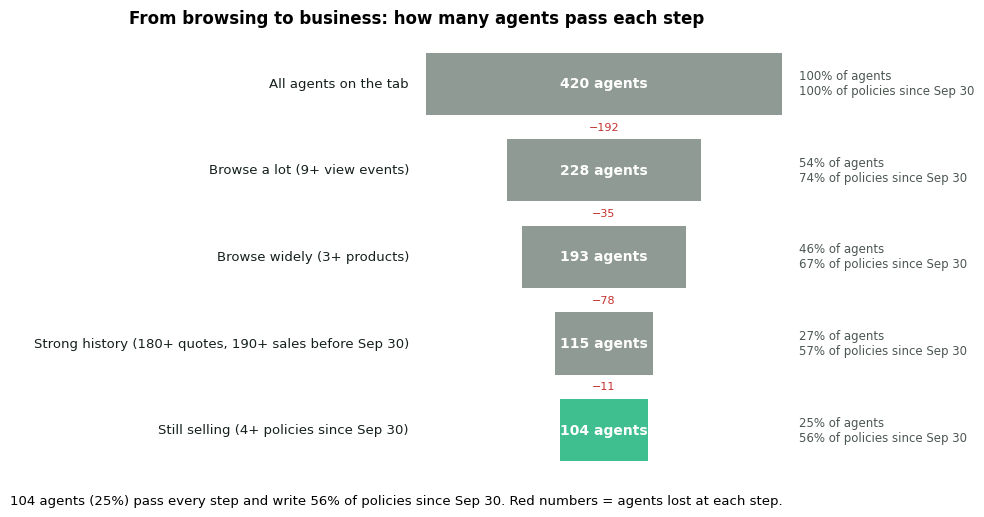

In [108]:
funnel = pd.DataFrame({
    "stage": [s for s, _ in stages],
    "agents": [m.sum() for _, m in stages],
    "policies_since": [droppers.loc[m, "sales_since_sep30"].sum() for _, m in stages],
    "median_viewed_per_sale": [droppers.loc[m, "viewed_per_sale"].median() for _, m in stages],
})
funnel["pct_of_all"] = funnel["agents"] / funnel["agents"].iloc[0] * 100
funnel["lost"] = -funnel["agents"].diff().fillna(0).astype(int)
funnel["pct_policies"] = funnel["policies_since"] / funnel["policies_since"].iloc[0] * 100
print("\n", funnel.round(1).to_string(index=False))
 
# Who drops out at the last step: browse a lot, strong history, but selling below the median now
followup = droppers.loc[stage4 & ~stage5,
                        ["user_name", "view_events", "products_viewed", "sales_since_sep30",
                         "sales_before_sept30", "quotes_alltime"]]
print("\nStrong history but selling below the median now:\n",
      followup.sort_values("sales_before_sept30", ascending=False).to_string(index=False))
 
# ---------------------------------------------------------------
# PART 3: FUNNEL CHART
# ---------------------------------------------------------------
GREEN, GREY = "#3fbf8f", "#8f9a94"
n = len(funnel)
fig, ax = plt.subplots(figsize=(10, 5.2))
 
for i, row in funnel.iterrows():
    width = row["agents"]
    ax.barh(i, width, left=-width / 2, height=0.72, color=GREEN if i == n - 1 else GREY)
    ax.text(0, i, f"{row['agents']:,} agents", ha="center", va="center",
            color="white", fontsize=10, fontweight="bold")
    ax.text(-230, i, row["stage"], ha="right", va="center", fontsize=9.5, color="#14201b")
    ax.text(230, i, f"{row['pct_of_all']:.0f}% of agents\n{row['pct_policies']:.0f}% of policies since Sep 30",
            ha="left", va="center", fontsize=8.5, color="#4b5751")
    if i > 0:
        ax.text(0, i - 0.5, f"−{row['lost']}", ha="center", va="center", fontsize=8,
                color="#c4312f", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
 
ax.set_xlim(-560, 420)
ax.set_ylim(n - 0.5, -0.6)
ax.axis("off")
ax.set_title("From browsing to business: how many agents pass each step",
             loc="left", fontweight="bold", x=0.0)
fig.text(0.01, 0.02, f"{funnel['agents'].iloc[-1]} agents ({funnel['pct_of_all'].iloc[-1]:.0f}%) pass every step "
         f"and write {funnel['pct_policies'].iloc[-1]:.0f}% of policies since Sep 30. "
         f"Red numbers = agents lost at each step.", fontsize=9.5)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig("plots/agent_funnel.png", dpi=200)
plt.show()